<a href="https://colab.research.google.com/github/Rutheniumruto/Signal-Processing-Lab-/blob/main/CN240_SF251_Lab02_Reading_Real_Signals_ipynb_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratory 2 — Reading Real Signals

**CN240 Data Science for Signal Processing · SF251 Introduction to Data Science**
Week 2 · Semester 1, Academic Year 2026 · Dr Surasak Phetmanee

---

| | |
|---|---|
| **Name** | *(your name here)* |
| **Student ID** | *(your ID here)* |
| **Section** | *(your section here)* |

## What you will do today

Last week you plotted your first signal. Today you read **three real recordings** — an ECG, an
accelerometer trace, and an audio clip — and answer the week-2 questions about each one:
*what is the sampling rate, how long is it, how many samples does it hold, and what noise can you already see?*

**Deliverables (due before week 3), pushed to your GitHub repository from Lab 1:**
1. This notebook, completed — all three signals loaded and plotted with labelled axes
2. The fact table in Task 4 filled in
3. Three sentences on noise in Task 5

> **Rule of the day:** every plot must have time in **seconds** on the x-axis — never the sample index.


## Setup

Run the two cells below first. The second cell creates the three data files in your working folder:

| File | Contents | Comes from |
|---|---|---|
| `ecg.csv` | 5 minutes of a real human ECG | MIT-BIH via `scipy.datasets` (synthetic fallback if offline) |
| `accel.csv` | 60 s of 3-axis movement: walking, then running | generated for this lab |
| `speech.wav` | 3 s speech-like audio clip | generated for this lab |

You do **not** need to understand the generator code — your work starts at Task 1.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import wavfile

plt.rcParams['figure.figsize'] = (12, 3.5)
plt.rcParams['axes.grid'] = True
print("NumPy", np.__version__, "· Pandas", pd.__version__)

NumPy 2.5.2 · Pandas 3.0.5


In [ ]:
# --- Lab data setup: run this cell once, do not edit -------------------------
rng = np.random.default_rng(240)

# 1) ECG ---------------------------------------------------------------------
ECG_FS = 360                                   # samples per second
try:                                           # real 5-minute MIT-BIH excerpt
    from scipy.datasets import electrocardiogram
    ecg_signal = electrocardiogram()           # millivolts
    ECG_SOURCE = "MIT-BIH (real recording)"
except Exception:                              # offline fallback: synthetic ECG
    t = np.arange(0, 300, 1 / ECG_FS)
    beat = lambda tt: 1.1 * np.exp(-((tt % 0.85) - 0.28) ** 2 / 0.0009)
    ecg_signal = (beat(t) - 0.25 * np.exp(-((t % 0.85) - 0.38) ** 2 / 0.004)
                  + 0.12 * np.sin(2 * np.pi * 0.3 * t)          # baseline wander
                  + 0.05 * np.sin(2 * np.pi * 50 * t)           # powerline hum
                  + 0.03 * rng.standard_normal(t.size))
    ECG_SOURCE = "synthetic (offline fallback)"
np.savetxt("ecg.csv", ecg_signal, fmt="%.5f")
print(f"ecg.csv     written · {ecg_signal.size} samples · source: {ECG_SOURCE}")

# 2) Accelerometer -----------------------------------------------------------
ACC_FS = 50
t = np.arange(0, 60, 1 / ACC_FS)
walk = t < 30                                  # first half walking, second half running
step_hz = np.where(walk, 1.8, 2.8)             # steps per second
phase = 2 * np.pi * np.cumsum(step_hz) / ACC_FS
amp = np.where(walk, 0.35, 1.1)
ax_ = amp * np.sin(phase) + 0.05 * rng.standard_normal(t.size)
ay_ = 0.6 * amp * np.sin(2 * phase + 0.7) + 0.05 * rng.standard_normal(t.size)
az_ = 1.0 + amp * np.abs(np.sin(phase / 2)) + 0.05 * rng.standard_normal(t.size)
spike = rng.random(t.size) < 0.001             # occasional motion artefacts
ax_[spike] += rng.choice([-3, 3], spike.sum())
pd.DataFrame({"time_s": t, "ax_g": ax_, "ay_g": ay_, "az_g": az_}).to_csv("accel.csv", index=False)
print(f"accel.csv   written · {t.size} samples · 3 axes at {ACC_FS} Hz")

# 3) Audio -------------------------------------------------------------------
AUD_FS = 44100
t = np.arange(0, 3.0, 1 / AUD_FS)
f0 = 140 + 25 * np.sin(2 * np.pi * 0.8 * t)                    # moving pitch
voiced = (np.sin(2 * np.pi * 2.2 * t) > -0.3).astype(float)    # syllable rhythm
audio = np.zeros_like(t)
for harmonic, weight in [(1, 1.0), (2, 0.55), (3, 0.35), (4, 0.2)]:
    audio += weight * np.sin(2 * np.pi * harmonic * np.cumsum(f0) / AUD_FS)
audio *= voiced * (0.55 + 0.45 * np.sin(2 * np.pi * 2.2 * t))
audio += 0.02 * rng.standard_normal(t.size)                    # room noise
audio16 = np.int16(audio / np.max(np.abs(audio)) * 0.9 * 32767)
wavfile.write("speech.wav", AUD_FS, audio16)
print(f"speech.wav  written · {audio16.size} samples · 16-bit at {AUD_FS} Hz")

ecg.csv     written · 108000 samples · source: MIT-BIH (real recording)
accel.csv   written · 3000 samples · 3 axes at 50 Hz
speech.wav  written · 132300 samples · 16-bit at 44100 Hz


---
## Task 1 — ECG *(worked example: read it, then run it)*

The ECG in `ecg.csv` is **one column of numbers — nothing else**. The file does not know its own
sampling rate: that information lives on the datasheet (here: **360 Hz**). This is exactly the
week-2 point — a discrete signal `x[n]` is just a list; *you* must supply the time axis.


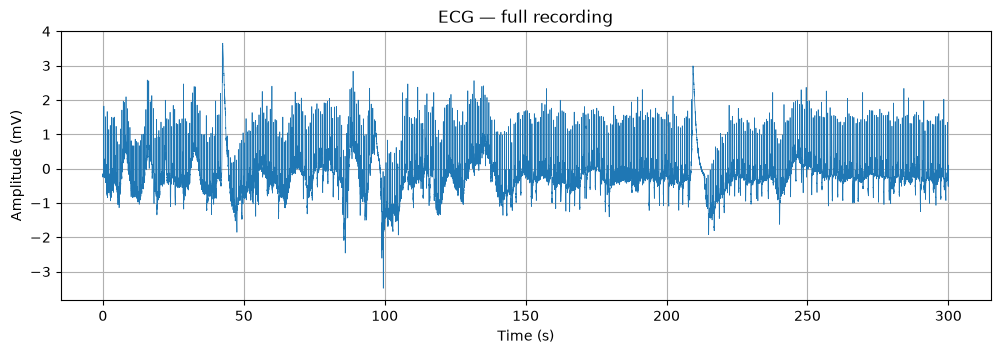

In [ ]:
ecg = np.loadtxt("ecg.csv")        # one value per line -> 1-D NumPy array
fs_ecg = 360                       # Hz, from the recording's documentation

t_ecg = np.arange(ecg.size) / fs_ecg          # sample index n  ->  time n / fs (seconds)

plt.plot(t_ecg, ecg, linewidth=0.5)
plt.xlabel("Time (s)"); plt.ylabel("Amplitude (mV)")
plt.title("ECG — full recording")
plt.show()

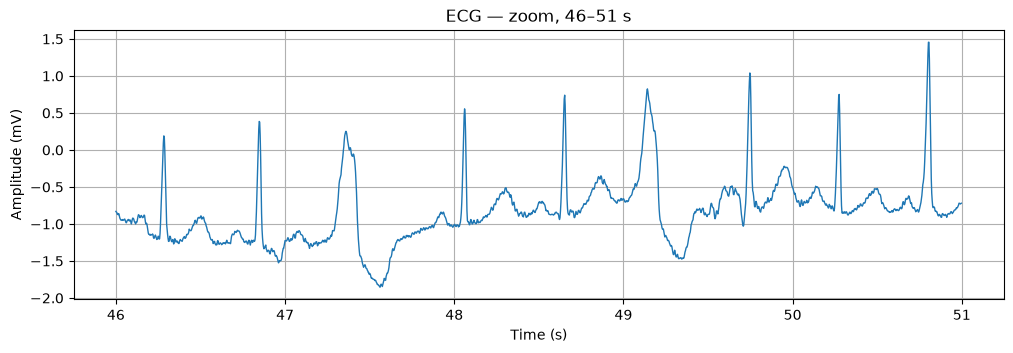

In [ ]:
# Zoom into five seconds: each sharp spike is one heartbeat (the QRS complex)
start, stop = 46, 51                              # seconds — try other windows too
sl = slice(int(start * fs_ecg), int(stop * fs_ecg))

plt.plot(t_ecg[sl], ecg[sl], linewidth=1)
plt.xlabel("Time (s)"); plt.ylabel("Amplitude (mV)")
plt.title(f"ECG — zoom, {start}–{stop} s")
plt.show()

**Q1.1 — In the zoomed plot, count the heartbeats and estimate the heart rate in beats per minute.**

*(your answer here)*

**Q1.2 — The recording is 5 minutes at 360 Hz. Before checking with code: how many samples must the array hold?**

*(your answer here — then verify: `ecg.size`)*


---
## Task 2 — Accelerometer *(guided: fill in the gaps)*

`accel.csv` is a **CSV with a header row and four columns** — so `pandas` is the right tool.
The subject walks for 30 s, then runs for 30 s.


In [ ]:
acc = pd.read_csv("accel.csv")
acc.head()                         # always look at the first rows before plotting

,time_s,ax_g,ay_g,az_g
0,0.00,0.097705,0.123340,1.085074
1,0.02,0.146063,0.246359,1.130365
2,0.04,0.273476,0.148556,1.104039
3,0.06,0.246017,0.182835,1.127745
4,0.08,0.307742,-0.009128,1.161945


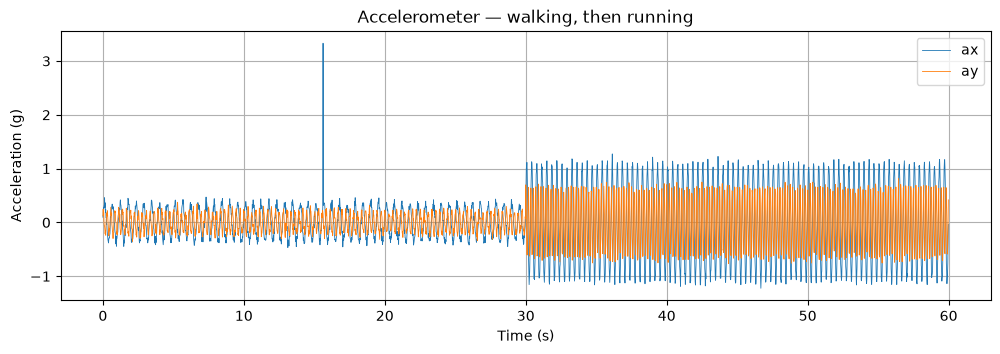

In [ ]:
fs_acc = 50                        # Hz

# TODO: plot all three axes against the time_s column, on one figure
plt.plot(acc["time_s"], acc["ax_g"], linewidth=0.6, label="ax")
plt.plot(acc["time_s"], acc["ay_g"], linewidth=0.6, label="ay")
# YOUR CODE HERE: add the az_g axis with a label

plt.xlabel("Time (s)"); plt.ylabel("Acceleration (g)")
plt.title("Accelerometer — walking, then running")
plt.legend()
plt.show()

In [ ]:
# YOUR CODE HERE (Task 2b):
# Zoom into TWO windows of 5 seconds each — one while walking (e.g. 10–15 s)
# and one while running (e.g. 40–45 s) — and plot ax_g for each.
# Hint: boolean masks work well:  m = (acc["time_s"] >= 10) & (acc["time_s"] < 15)


**Q2.1 — How does running differ from walking in this signal? Mention both amplitude and frequency.**

*(your answer here)*

**Q2.2 — You should spot a few isolated spikes of ±3 g. Which noise type from the lecture is this?**

*(your answer here)*


---
## Task 3 — Audio *(on your own)*

A WAV file is the one format today that **carries its own sampling rate in the file header** —
`wavfile.read` returns it for you. Note the dtype too: 16-bit integers, exactly as quantisation
left them.


In [ ]:
fs_aud, audio = wavfile.read("speech.wav")
print("Sampling rate from the file header:", fs_aud, "Hz")
print("Data type:", audio.dtype, "-> 16-bit quantisation, 65,536 levels")

audio_f = audio / 32768.0          # convert to floats in [-1, 1] for analysis

# YOUR CODE HERE (Task 3a): plot the full 3-second waveform against time in seconds


Sampling rate from the file header: 44100 Hz
Data type: int16 -> 16-bit quantisation, 65,536 levels


In [ ]:
# YOUR CODE HERE (Task 3b):
# Zoom into 30 MILLISECONDS anywhere inside a syllable (e.g. 1.000–1.030 s).
# At this scale you can see the individual oscillations of the voice.


**Q3.1 — From your 30 ms zoom, estimate the period of one oscillation, and from it the pitch in Hz.**

*(your answer here — pitch ≈ 1 / period)*

**Q3.2 — Audio uses 44,100 Hz but the accelerometer only 50 Hz. Explain both numbers with the Nyquist rule.**

*(your answer here)*


---
## Task 4 — The fact table

Complete the table using code (a few helpers below), the file itself, or the values given in Setup.

| | Sampling rate (Hz) | Duration (s) | Number of samples | Bit depth |
|---|---|---|---|---|
| **ECG** | | | | 64-bit float (from CSV) |
| **Accelerometer** | | | | 64-bit float (from CSV) |
| **Audio** | | | | |


In [ ]:
# Helpers — extend as you like
print("ECG    :", ecg.size, "samples ·", ecg.size / fs_ecg, "s")
print("Accel  :", len(acc), "samples ·", len(acc) / fs_acc, "s")
print("Audio  :", audio.size, "samples ·", audio.size / fs_aud, "s ·", audio.dtype)

ECG    : 108000 samples · 300.0 s
Accel  : 3000 samples · 60.0 s
Audio  : 132300 samples · 3.0 s · int16


---
## Task 5 — Three sentences on noise

Look back at your three full-length plots. For **each signal**, write **one sentence** naming the
noise you can already see and where it appears (use the four noise types from the lecture:
electronic/thermal, powerline hum, baseline wander, motion artefact).

1. **ECG:** *(your sentence here)*
2. **Accelerometer:** *(your sentence here)*
3. **Audio:** *(your sentence here)*


---
## Bonus (optional) — put a number on quality

Estimate the SNR of the ECG with a quick engineering trick: treat the sample-to-sample
difference as (mostly) noise.


In [ ]:
noise_est = np.diff(ecg) / np.sqrt(2)          # rough noise estimate
snr_db = 10 * np.log10(np.var(ecg) / np.var(noise_est))
print(f"Estimated ECG SNR ≈ {snr_db:.1f} dB")
# Compare with the lecture bands: > 40 dB clean · 20–40 dB usable · < 10 dB buried

Estimated ECG SNR ≈ 21.7 dB


---
## Before you submit

- [ ] Every plot has **time in seconds** on the x-axis and labelled y-axis
- [ ] All `YOUR CODE HERE` cells are completed and run without errors
- [ ] All questions (Q1–Q3), the fact table, and the three noise sentences are answered
- [ ] Run **Runtime → Restart and run all** — the notebook must run top to bottom cleanly
- [ ] Commit and push this notebook to your **GitHub repository from Lab 1**

*Next week: Cleaning Real Data — you will remove the very noise you described today.*
